# IDSSE 01 — parse, verify labels, controlled possession

First notebook of the IDSSE training track ([docs/IDSSE_PLAN.md](../docs/IDSSE_PLAN.md)). It covers T1 and W3:

1. which IDSSE matches are complete on disk,
2. parse the positions XML into arrays (`src/idsse/parse.py`, cached in `cache/idsse/`),
3. check what the DFL flags mean: `BallPossession` value of the home team, `M`, `BallStatus`,
4. possession and stoppage statistics of the raw labels,
5. the controlled-possession relabel (give back short spells) and what it does to the counts.

No BAR-ATH data or labels are read here. The only BAR-ATH numbers quoted are published ones
(DATA.md, EVALUATION.md) and label-free ETL / detector aggregates from `docs/PLAN.md`.

In [1]:
import os, sys
ROOT = os.path.abspath("..") if os.path.basename(os.getcwd()) == "eda" else os.getcwd()
sys.path.insert(0, ROOT)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.idsse import download, parse, labels

FPS = parse.FPS
pd.set_option("display.width", 160)

## 0. Download / repair

`download.ensure()` asks the figshare API (article 28196177, CC BY 4.0) for every file's size and MD5
and downloads again anything missing or the wrong size (truncated files, saved error pages). Each
download is checked against the MD5 before it replaces the local file. Files already correct are left
alone, so re-running is cheap. Set `VERIFY_MD5 = True` to also hash the files that look fine (~20 s).

Target folder: `$IDSSE_DIR`, else the existing `external-data/idsse`, else `external-data/idsse` in the
repo (gitignored). Full dataset ~2.6 GB.

In [2]:
DOWNLOAD = True        # False: only check, download nothing
VERIFY_MD5 = False

dl = pd.DataFrame(download.ensure(verify_md5=VERIFY_MD5, dry_run=not DOWNLOAD))
print("IDSSE data:", download.target_dir())
dl[dl.action != "ok"] if (dl.action != "ok").any() else print("all", len(dl), "files match figshare")

IDSSE data: D:\Code\personal\barcelona-hackathon\external-data\idsse
all 21 files match figshare


## 1. Inventory

A file is complete when it ends with the closing `</PutDataRequest>`. After section 0 all 7 matches
should be usable.

In [3]:
inv = pd.DataFrame(parse.inventory())
inv

,match,info_mb,info_ok,events_mb,events_ok,positions_mb,positions_ok,usable
0,J03WMX,0.0,True,0.8,True,418.5,True,True
1,J03WN1,0.0,True,0.6,True,391.7,True,True
2,J03WOH,0.0,True,0.6,True,348.9,True,True
3,J03WOY,0.0,True,0.7,True,362.6,True,True
4,J03WPY,0.0,True,0.7,True,371.7,True,True
5,J03WQQ,0.0,True,0.7,True,356.2,True,True
6,J03WR9,0.0,True,0.7,True,372.9,True,True


In [4]:
MATCHES = inv.loc[inv.usable, "match"].tolist()
print(len(MATCHES), "usable:", MATCHES)
print("to download again:", inv.loc[~inv.usable, "match"].tolist())

7 usable: ['J03WMX', 'J03WN1', 'J03WOH', 'J03WOY', 'J03WPY', 'J03WQQ', 'J03WR9']
to download again: []


## 2. Parse

About 5 s per match the first time, then read from `cache/idsse/<match>.npz`. Referees are dropped.

In [5]:
M = {mid: parse.load_match(mid) for mid in MATCHES}

rows = []
for mid, m in M.items():
    on = np.isfinite(m["xy"][..., 0])
    rows.append({
        "match": mid,
        "home": m["meta"]["home_name"], "away": m["meta"]["away_name"],
        "result": m["meta"]["result"], "competition": m["meta"]["competition"],
        "sections": len(m["meta"]["sections"]),
        "minutes": round(len(m["half"]) / FPS / 60, 1),
        "persons": len(m["person_id"]),
        "home_on_pitch": round(on[:, m["person_team"] == 0].sum(1).mean(), 2),
        "away_on_pitch": round(on[:, m["person_team"] == 1].sum(1).mean(), 2),
        "ball_present_%": round(100 * np.isfinite(m["ball"][:, 0]).mean(), 2),
        "pitch": m["meta"]["pitch"],
    })
summary = pd.DataFrame(rows).set_index("match")
summary

,home,away,result,competition,sections,minutes,persons,home_on_pitch,away_on_pitch,ball_present_%,pitch
match,,,,,,,,,,,
J03WMX,1. FC Köln,FC Bayern München,1:2,Bundesliga,2,97.3,32,11.0,11.00,100.0,"[105.0, 68.0]"
J03WN1,VfL Bochum 1848,Bayer 04 Leverkusen,3:0,Bundesliga,2,94.4,29,11.0,10.07,100.0,"[105.0, 68.0]"
J03WOH,Fortuna Düsseldorf,SSV Jahn Regensburg,4:0,2. Bundesliga,2,91.5,32,11.0,11.00,100.0,"[105.0, 68.0]"
J03WOY,Fortuna Düsseldorf,F.C. Hansa Rostock,3:1,2. Bundesliga,2,95.0,32,11.0,11.00,100.0,"[105.0, 68.0]"
J03WPY,Fortuna Düsseldorf,1. FC Nürnberg,0:1,2. Bundesliga,2,97.5,31,11.0,11.00,100.0,"[105.0, 68.0]"
J03WQQ,Fortuna Düsseldorf,FC St. Pauli,1:0,2. Bundesliga,2,94.9,31,11.0,10.63,100.0,"[105.0, 68.0]"
J03WR9,Fortuna Düsseldorf,1. FC Kaiserslautern,1:2,2. Bundesliga,2,97.9,31,11.0,11.00,100.0,"[105.0, 68.0]"


Clean corrected tracking: ~11 per team and the ball on (almost) every frame. BAR-ATH ATD by contrast:
ball on 59.3% of graded frames, ~10.1 tracked per team, ~10% of positions guessed. Closing that gap
is the degrader's job (W2).

## 3. What the DFL flags mean

### 3a. `M` is the match minute

In [6]:
m = M[MATCHES[0]]
for h in np.unique(m["half"]):
    mm = m["minute"][(m["half"] == h) & (m["minute"] >= 0)]
    print(f"half {h}: M from {mm.min()} to {mm.max()}, frames per minute (median) "
          f"{np.median(np.bincount(mm)[np.bincount(mm) > 0]):.0f}  (60 s x 25 fps = 1500)")

half 1: M from 1 to 48, frames per minute (median) 1500  (60 s x 25 fps = 1500)
half 2: M from 46 to 96, frames per minute (median) 1500  (60 s x 25 fps = 1500)


### 3b. Which `BallPossession` value is home?

Data-driven check: on live frames where a player is within 1 m of the ball, cross-tab the flag against
that player's team (from the match information). The diagonal should dominate.

In [7]:
rows = []
for mid, m in M.items():
    nt = labels.nearest_player_team(m, max_dist=1.0)
    ok = (m["status"] == 1) & (nt >= 0)
    for v in (1, 2):
        sel = ok & (m["poss"] == v)
        rows.append({"match": mid, "BallPossession": v,
                     "nearest_home": int((nt[sel] == 0).sum()),
                     "nearest_away": int((nt[sel] == 1).sum())})
xt = pd.DataFrame(rows)
xt["home_share"] = (xt.nearest_home / (xt.nearest_home + xt.nearest_away)).round(3)
xt

,match,BallPossession,nearest_home,nearest_away,home_share
0,J03WMX,1,13843,1306,0.914
1,J03WMX,2,1010,18602,0.051
2,J03WN1,1,11830,1498,0.888
3,J03WN1,2,1306,12164,0.097
4,J03WOH,1,13353,1136,0.922
5,J03WOH,2,1095,11742,0.085
6,J03WOY,1,13759,1299,0.914
7,J03WOY,2,1404,12562,0.101
8,J03WPY,1,19094,1090,0.946
9,J03WPY,2,1154,11159,0.094


In [8]:
tot = xt.groupby("BallPossession")[["nearest_home", "nearest_away"]].sum()
home_share = tot.nearest_home / tot.sum(axis=1)
HOME_VALUE = int(home_share.idxmax())
assert home_share[HOME_VALUE] > 0.8 and home_share.drop(HOME_VALUE).iloc[0] < 0.2, home_share
print("BallPossession home value =", HOME_VALUE, "| home share by value:", home_share.round(3).to_dict())

BallPossession home value = 1 | home share by value: {1: 0.925, 2: 0.082}


The ~8% off-diagonal is expected, not an error: a player near the ball is not always its owner
(duels, passes flying past, the moment before a change). That gap is exactly the "contact vs control"
ambiguity the challenge talks about.

### 3c. `BallStatus`: stoppages and ball-in-play time

In [9]:
CODES = {mid: labels.frame_codes(m, HOME_VALUE) for mid, m in M.items()}

def stoppage_stats(codes, half):
    sp = labels.spells(codes, half)
    dead = sp[sp[:, 2] == labels.D]
    live_min = (codes != labels.D).sum() / FPS / 60
    return {"ball_in_play_min": round(live_min, 1),
            "dead_%": round(100 * (codes == labels.D).mean(), 1),
            "stoppages": len(dead),
            "stoppages_>=1s": int((dead[:, 4] >= FPS).sum()),
            "stoppage_s_p10": round(np.percentile(dead[:, 4], 10) / FPS, 1),
            "stoppage_s_p50": round(np.percentile(dead[:, 4], 50) / FPS, 1),
            "stoppage_s_p90": round(np.percentile(dead[:, 4], 90) / FPS, 1)}

stop = pd.DataFrame({mid: stoppage_stats(CODES[mid], M[mid]["half"]) for mid in M}).T
stop

,ball_in_play_min,dead_%,stoppages,stoppages_>=1s,stoppage_s_p10,stoppage_s_p50,stoppage_s_p90
J03WMX,56.9,41.5,103.0,103.0,5.0,15.5,48.9
J03WN1,45.6,51.7,107.0,105.0,5.4,23.8,49.2
J03WOH,48.0,47.6,102.0,102.0,6.2,19.1,52.6
J03WOY,50.9,46.5,113.0,112.0,4.5,19.2,48.6
J03WPY,54.3,44.3,97.0,97.0,5.6,22.8,55.4
J03WQQ,56.2,40.7,99.0,99.0,7.9,19.6,43.4
J03WR9,56.9,41.9,92.0,92.0,7.9,20.0,48.1


For reference (label-free, from `docs/PLAN.md`): our BAR-ATH dead-ball detector finds 87 stoppages and
60.3 min of ball in play over the graded frames; a typical match has ~100–130 stoppages and 52–58 min.

Note: the IDSSE timeline is whole halves from the first to the last tracked frame, so a few dead
frames before kickoff / after the whistle may be included. The BAR-ATH graded window also starts 117 s
before the 2nd-half kickoff (all `D`), so this is close to how the GT counts.

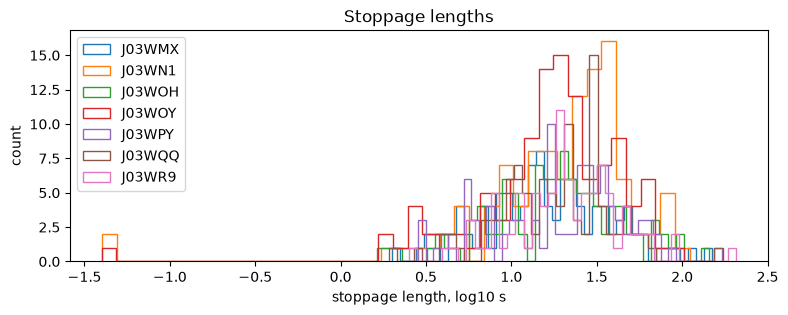

In [10]:
fig, ax = plt.subplots(figsize=(9, 3))
for mid in M:
    sp = labels.spells(CODES[mid], M[mid]["half"])
    d = sp[sp[:, 2] == labels.D, 4] / FPS
    ax.hist(np.log10(d), bins=40, histtype="step", label=mid)
ax.set_xlabel("stoppage length, log10 s"); ax.set_ylabel("count"); ax.legend(); ax.set_title("Stoppage lengths")
plt.show()

## 4. Raw possession spells

A possession (the ranking metric's object) is a maximal run of `H` or of `A`. Published reference:
the BAR-ATH public window has **17 possessions, mean 14.2 s** over 5 minutes (DATA.md); the shortest
spell seen there is 0.76 s (PLAN.md). Five minutes is a tiny sample: a sanity reference, not a target.

In [11]:
def possession_stats(codes, half):
    sp = labels.spells(codes, half)
    pos = sp[sp[:, 2] != labels.D]
    live_min = (codes != labels.D).sum() / FPS / 60
    dur = pos[:, 4] / FPS
    # a change of hands inside live play: H directly followed by A (or back), same half
    flips = int(sum(((sp[i, 2] != labels.D) & (sp[i + 1, 2] != labels.D) & (sp[i, 3] == sp[i + 1, 3]))
                    for i in range(len(sp) - 1)))
    return {"possessions": len(pos), "per_live_min": round(len(pos) / live_min, 2),
            "live_turnovers": flips,
            "mean_s": round(dur.mean(), 1), "median_s": round(np.median(dur), 1),
            "<1s_%": round(100 * (dur < 1).mean(), 1), "<2s_%": round(100 * (dur < 2).mean(), 1),
            "<3s_%": round(100 * (dur < 3).mean(), 1),
            "home_%": round(100 * (codes == labels.H).sum() / (codes != labels.D).sum(), 1)}

raw = pd.DataFrame({mid: possession_stats(CODES[mid], M[mid]["half"]) for mid in M}).T
raw

,possessions,per_live_min,live_turnovers,mean_s,median_s,<1s_%,<2s_%,<3s_%,home_%
J03WMX,511.0,8.98,408.0,6.7,3.0,16.8,37.4,49.7,45.8
J03WN1,500.0,10.97,394.0,5.5,3.1,15.2,34.2,47.6,53.3
J03WOH,402.0,8.38,301.0,7.2,3.9,11.4,27.4,39.1,54.4
J03WOY,456.0,8.97,344.0,6.7,3.6,9.0,28.1,43.2,49.6
J03WPY,421.0,7.75,324.0,7.7,3.8,13.5,29.5,41.6,62.8
J03WQQ,401.0,7.13,302.0,8.4,4.7,9.2,25.2,38.7,43.9
J03WR9,370.0,6.51,278.0,9.2,4.2,11.1,25.4,38.4,62.4


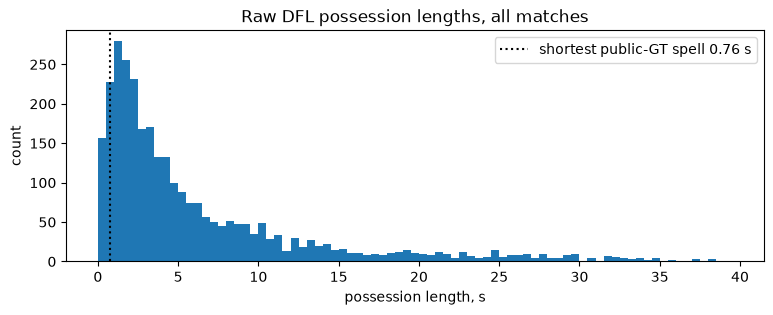

In [12]:
fig, ax = plt.subplots(figsize=(9, 3))
dur = np.concatenate([labels.spells(CODES[mid], M[mid]["half"]) for mid in M])
dur = dur[dur[:, 2] != labels.D, 4] / FPS
ax.hist(dur, bins=np.arange(0, 40, 0.5))
ax.axvline(0.76, color="k", ls=":", label="shortest public-GT spell 0.76 s")
ax.set_xlabel("possession length, s"); ax.set_ylabel("count"); ax.legend()
ax.set_title("Raw DFL possession lengths, all matches")
plt.show()

## 5. Controlled possession: give back short spells

`labels.give_back`: a spell of one team shorter than τ, with the other team directly on both sides and
no dead ball in between, is given back to that team (a touch or deflection without control). Spells
next to a dead ball are left alone (e.g. a deflection out of play).

τ is **not** picked here by matching a score. It will be chosen on the IDSSE bench (W5) within the
1.5–3 s range other teams found; this table only shows how strongly τ moves the counts.

In [13]:
TAUS_S = [0, 0.5, 1.0, 1.5, 2.0, 3.0]
rows = []
for before_dead in (False, True):
    for tau in TAUS_S:
        for mid in M:
            c = (labels.give_back(CODES[mid], M[mid]["half"], int(round(tau * FPS)), before_dead)
                 if tau else CODES[mid])
            st = possession_stats(c, M[mid]["half"])
            st.update(match=mid, before_dead=before_dead, tau_s=tau,
                      frames_changed_=int((c != CODES[mid]).sum()))
            rows.append(st)
sweep = pd.DataFrame(rows)
sweep.groupby(["before_dead", "tau_s"])[["possessions", "per_live_min", "mean_s", "median_s", "<1s_%",
                                         "<2s_%", "frames_changed_"]].mean().round(2)

possessions  per_live_min  mean_s  median_s  <1s_%  <2s_%  frames_changed_
before_dead tau_s                                                                            
False       0.0         437.29          8.38    7.34      3.76  12.31  29.60             0.00
            0.5         415.00          7.96    7.73      4.01   9.49  26.63            55.71
            1.0         386.43          7.41    8.27      4.49   6.01  22.64           333.00
            1.5         351.00          6.72    9.07      5.16   6.39  18.29           923.71
            2.0         322.71          6.18    9.84      5.84   6.73  14.91          1622.86
            3.0         277.86          5.33   11.44      7.07   7.44  15.37          3173.57
True        0.0         437.29          8.38    7.34      3.76  12.31  29.60             0.00
            0.5         409.00          7.84    7.83      4.10   8.10  25.49            98.86
            1.0         365.29          7.00    8.73      4.90   0.59  17.79           647.86
            1.5         321.29          6.15    9.91      5.93   0.61   9.87          1518.57
            2.0         288.14          5.52   11.04      6.87   0.60   4.16          2445.14
            3.0         237.14          4.55   13.43      8.83   0.61   3.43          4456.29

### Rule 2: short spell just before a dead ball

The table above with `before_dead=True` adds a second rule: a short spell between the other team and a
dead ball (a touch or deflection just before the ball goes out) also goes back. A short spell right
**after** a dead ball is never changed: after a restart the restarting team has the ball (CHALLENGE.md).

In [14]:
# what the remaining short spells look like at tau = 2 s: are they next to a dead ball?
TAU_DEFAULT = 2.0
rows = []
for mid in M:
    c = labels.give_back(CODES[mid], M[mid]["half"], int(TAU_DEFAULT * FPS))  # rule 1 only
    sp = labels.spells(c, M[mid]["half"])
    for i in range(len(sp)):
        if sp[i, 2] == labels.D or sp[i, 4] >= TAU_DEFAULT * FPS:
            continue
        prev_d = i == 0 or sp[i - 1, 2] == labels.D or sp[i - 1, 3] != sp[i, 3]
        next_d = i == len(sp) - 1 or sp[i + 1, 2] == labels.D or sp[i + 1, 3] != sp[i, 3]
        rows.append({"match": mid, "before": "D" if prev_d else "team", "after": "D" if next_d else "team"})
pd.DataFrame(rows).value_counts(["before", "after"]).rename("short spells left (< 2 s)")

before  after
team    D        242
D       team      92
        D          5
Name: short spells left (< 2 s), dtype: int64

## Findings so far

From the run on 2026-11-15, all 7 matches (2 Bundesliga, 5 2. Bundesliga; Fortuna Düsseldorf is home
in 5 of them, so check later that the team head does not learn one club):

- **All 7 usable** after section 0 (WPY, WQQ, WR9 were downloaded again and match figshare's MD5).
- **`BallPossession` 1 = home**, 2 = away. The player within 1 m of the ball is from the flagged team on
  89–95% of live frames.
- **`M` = match minute** (1,500 frames per minute; 46 appears in both halves).
- **Stoppages look like football:** 92–113 per match, 46–57 min ball in play, median stoppage 16–24 s.
  BallStatus is a usable `D` label as it is. Our BAR-ATH detector (87 stoppages, 60.3 min) sits at the
  low end of the stoppage count and the high end of the ball-in-play time: probably some short stoppages
  missed, as PLAN.md already suspects.
- **Raw DFL possession is too jumpy:** ~8.4 possessions per live minute, mean 7.3 s, 12% shorter than
  1 s. The public window, for scale only (17 possessions in ~4 min of live play), is ~4 per live minute,
  mean 14.2 s. That matches the fork scan's "DFL switches about 2× as often".
- **Rule 1 alone (give back A-B-A spells) does not close the gap:** τ = 2 s → 6.2 per live minute,
  mean 9.9 s; τ = 3 s → 5.3, mean 11.5 s. Most short spells left over sit **just before a dead ball**:
  a last touch before the ball goes out.
- **Rules 1 + 2 together** (also give back a short spell before a dead ball): τ = 2 s → 5.5 per live
  minute, mean 11.0 s; τ = 3 s → 4.6, mean 13.4 s. That is now in the range of the public window's ~4
  per live minute. **We do not pick τ from this match-up** (5 minutes, 17 possessions; RULES.md): it is
  chosen on the IDSSE bench, within 1.5–3 s.
- Still open: variant B (change only at DFL control events from `events_raw`), to compare against
  rules 1 + 2 on the bench.

## Next

- **W1**: adapter to ATD-shaped arrays (`raw_players [N, 46, 3]` normalised, speed NaN = guessed)
  so the etl-v1.3 features run unchanged; needs `N_FRAMES` / half blocks parameterised in the ETL.
- **W2**: degrader v0 (virtual camera, ball loss, guessed positions), calibrated to `cache/report.txt`.
- **W3 variant B**: possession changes only at DFL control events (`events_raw`).